In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.OPTIMIZER_NAME,
            config.LEARNING_RATE
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    Visualizer.showComparativeTable(results_together)


# Obiamente si corremos TODAS las combinaciones tenemos 240 expies que a ~70s mins cada uno son como 5 horas entonces podemos seleccionar parametros que afectan en conjuntos seleccionar el mejor y correr los siguentes. Ejemplo batchSize es importante para Adam entonces corremos opti y batches juntos, selecccionamos el mejor y testeamos los otros.

opti = [
    ("SGD", 0.001),
    ("SGD", 0.01),
    ("SGD", 0.1),
    ("Adam", 0.0001),
    ("Adam", 0.001),
    ("Adam", 0.01)
]

batches = [
    64,
    100,
    256,
    512
]

neurons = [
    # (64, 32),
    (128, 64),
    # (256, 128),
    # (512, 256)
]

dropout = [
    # 0,
    0.2,
    # 0.5
]


def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=1,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
            show_init=True,
            # show_epoch_data=True,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies




In [2]:
expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 3




========== CONFIGURATION ==========
Seed:             42
Batch size:       64
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.001
neuron_1:        64
neuron_2:        32

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 13.22 seconds

Peak GPU memory: 18.00 MB

Test CEL: 2.12226
Test accuracy: 35.81%

----------------- SGD-0.001/64-32/B64/D0.2 -----------------


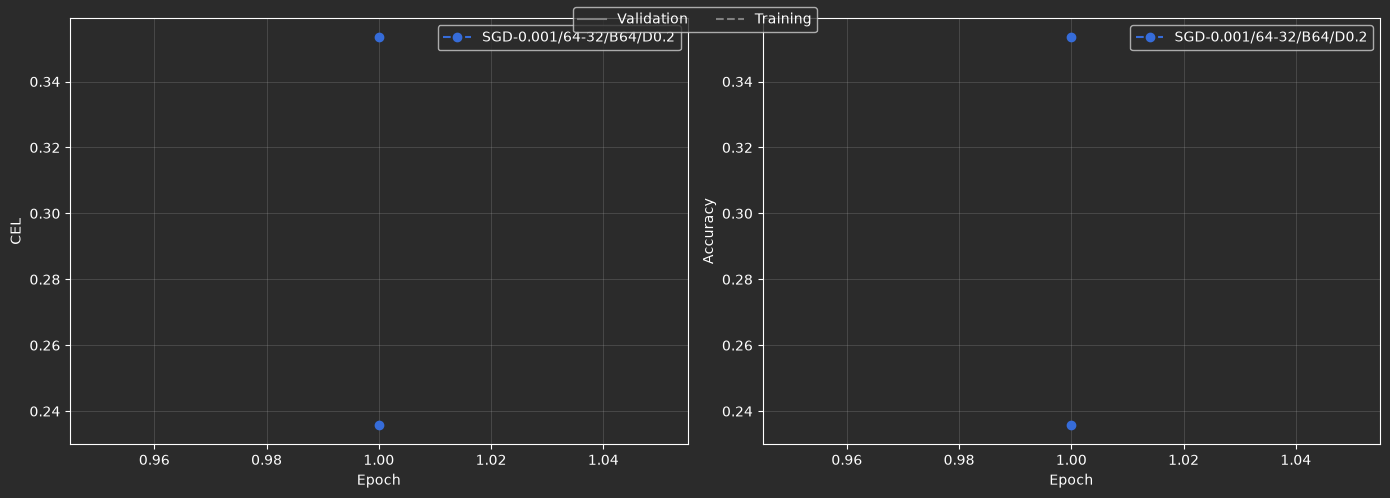

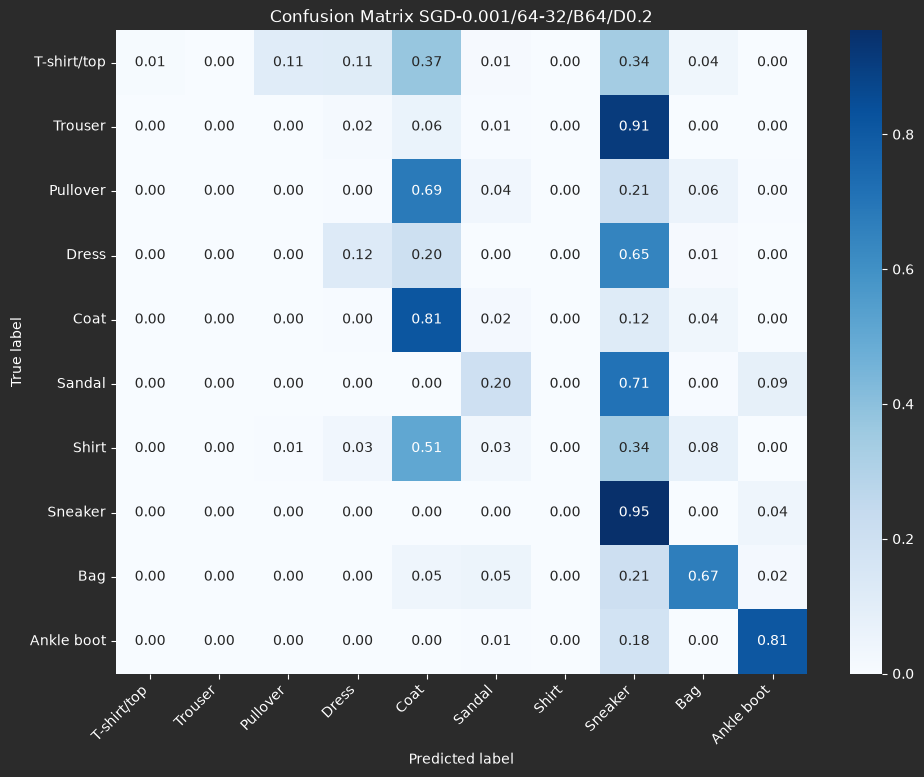


========== CONFIGURATION ==========
Seed:             42
Batch size:       64
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.01
neuron_1:        64
neuron_2:        32

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 10.32 seconds

Peak GPU memory: 18.40 MB

Test CEL: 0.76969
Test accuracy: 72.91%

----------------- SGD-0.01/64-32/B64/D0.2 -----------------


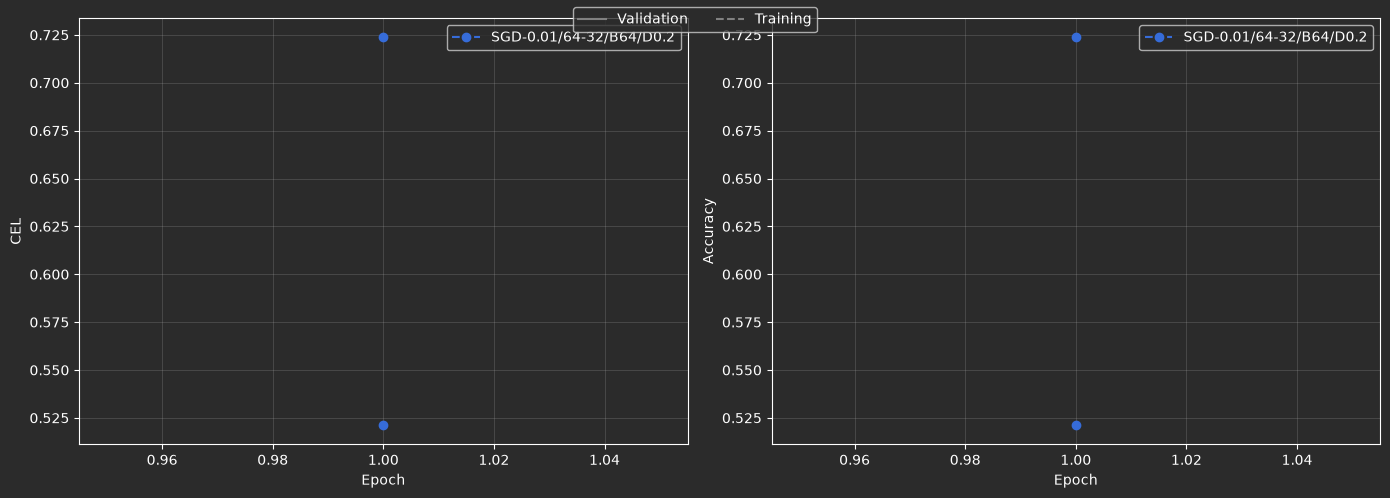

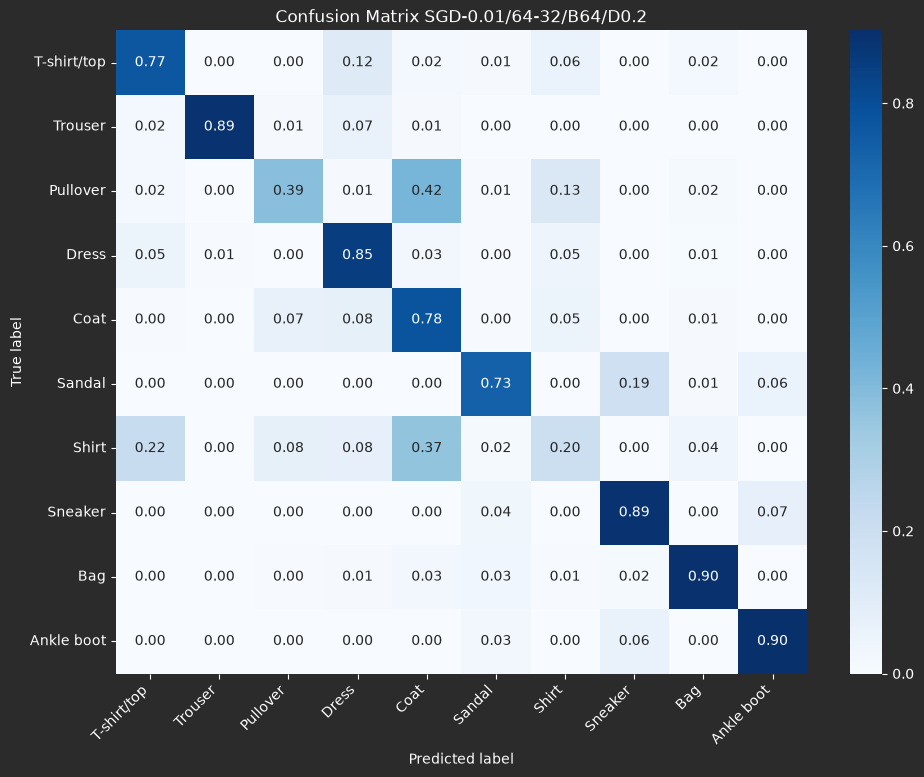


========== CONFIGURATION ==========
Seed:             42
Batch size:       64
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.1
neuron_1:        64
neuron_2:        32

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 10.55 seconds

Peak GPU memory: 18.81 MB

Test CEL: 1.05294
Test accuracy: 64.97%

----------------- SGD-0.1/64-32/B64/D0.2 -----------------


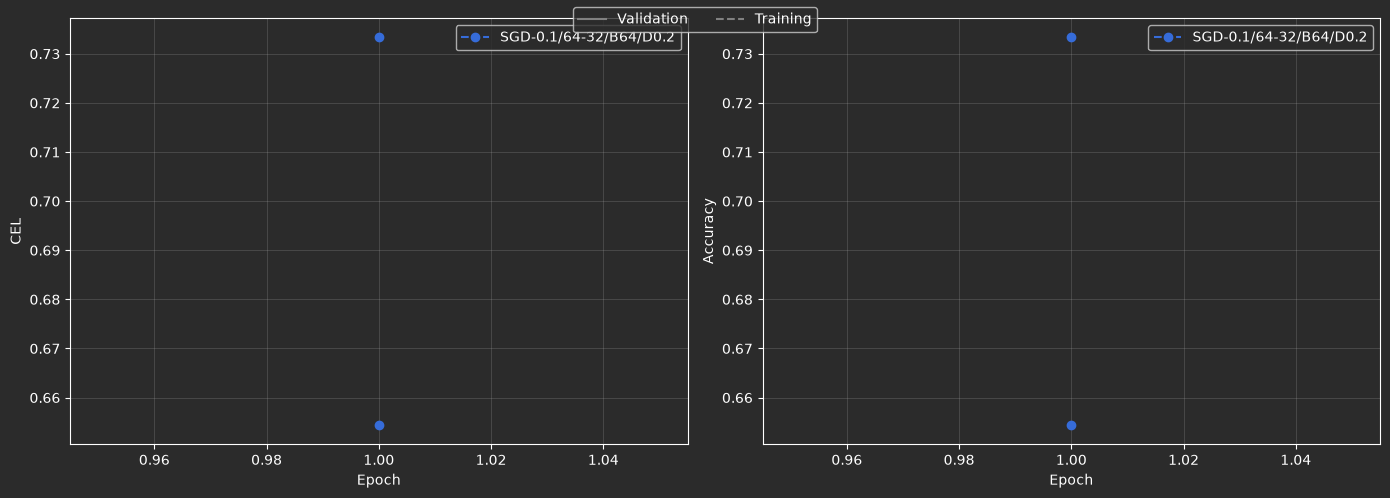

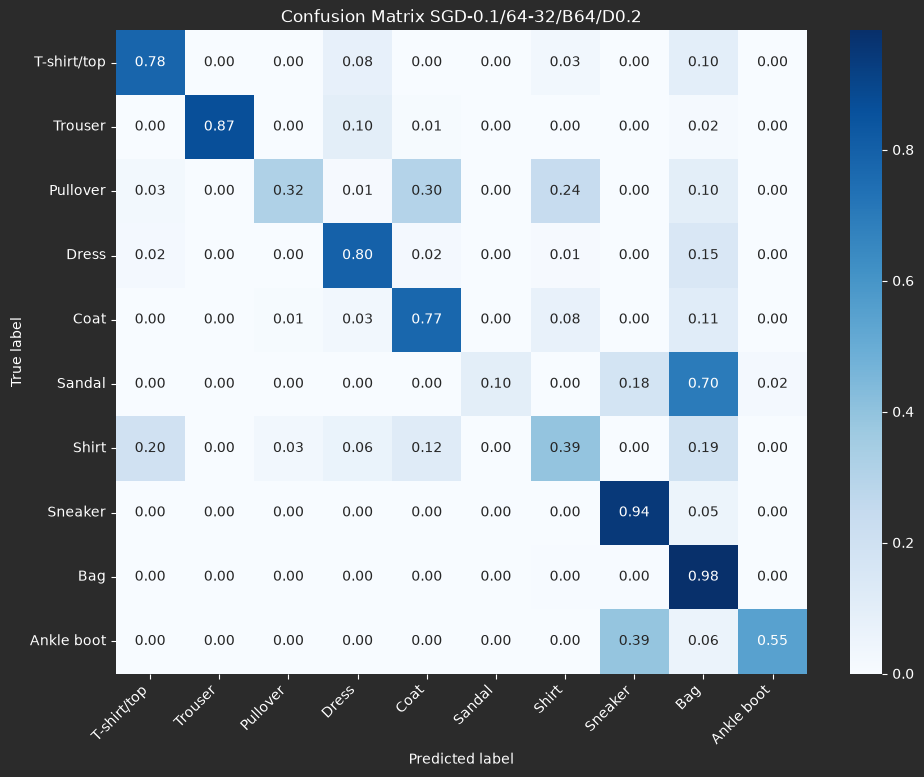

In [3]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: ('SGD', 0.001):-----------------------------------

----------------- SGD-0.001/64-32/B64/D0.2 -----------------


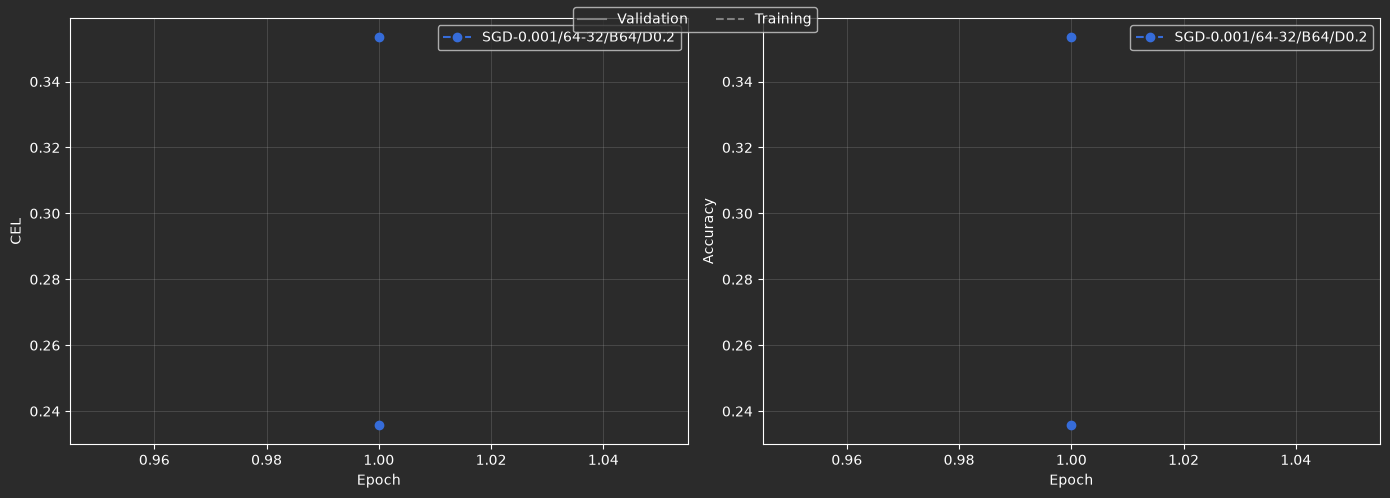

                          Train Loss  Valid Loss  Train Accuracy  Valid Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Worst Class Recall  Generalization Gap  Loss Gap  CM Deviation  Training Time  GPU max VRAM
SGD-0.001/64-32/B64/D0.2        2.23        2.12            0.24            0.35           0.36             0.36          0.36      0.28                0.00               -0.12     -0.11          8.66          13.22         18.00

--- Best experiments ---
Max Test Accuracy      -> SGD-0.001/64-32/B64/D0.2: 0.3581
Max Valid Accuracy     -> SGD-0.001/64-32/B64/D0.2: 0.3534
Max Macro F1           -> SGD-0.001/64-32/B64/D0.2: 0.2809
Best Worst-Class Recall -> SGD-0.001/64-32/B64/D0.2: 0.0000
Min CM Deviation       -> SGD-0.001/64-32/B64/D0.2: 8.6642
Min Training Time       -> SGD-0.001/64-32/B64/D0.2: 13.2s
Min VRAM       -> SGD-0.001/64-32/B64/D0.2: 17.9990234375 MB

-----------------------------------GROUP: ('SGD', 0.01):-----------------------------------

----

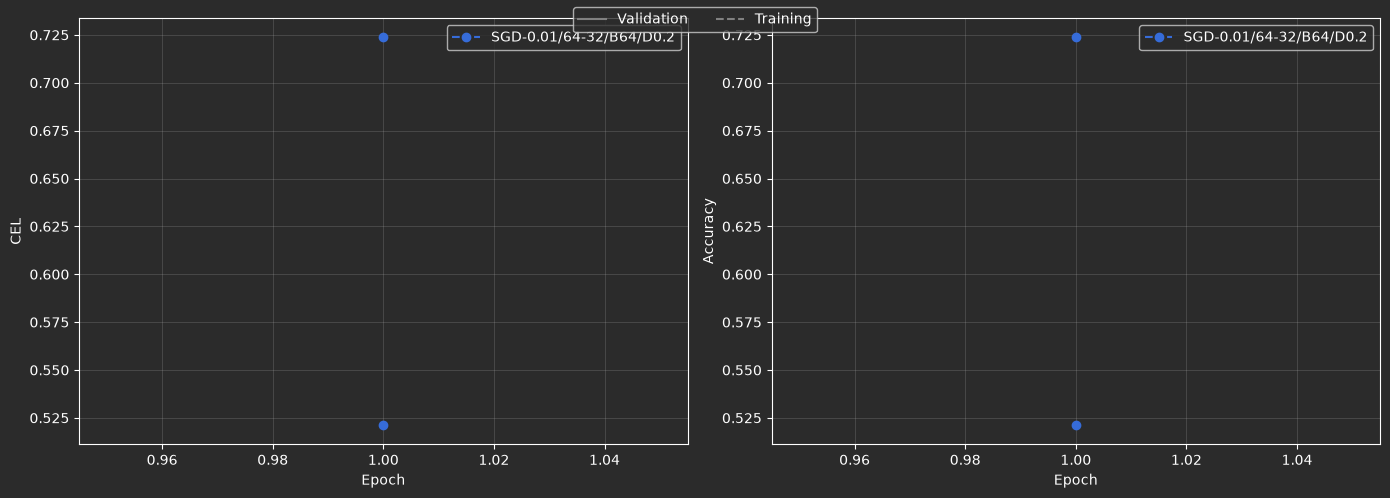

                         Train Loss  Valid Loss  Train Accuracy  Valid Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Worst Class Recall  Generalization Gap  Loss Gap  CM Deviation  Training Time  GPU max VRAM
SGD-0.01/64-32/B64/D0.2        1.37        0.77            0.52            0.72           0.73             0.73          0.73      0.72                0.20               -0.20     -0.60          1.75          10.32         18.40

--- Best experiments ---
Max Test Accuracy      -> SGD-0.01/64-32/B64/D0.2: 0.7291
Max Valid Accuracy     -> SGD-0.01/64-32/B64/D0.2: 0.7237
Max Macro F1           -> SGD-0.01/64-32/B64/D0.2: 0.7167
Best Worst-Class Recall -> SGD-0.01/64-32/B64/D0.2: 0.2000
Min CM Deviation       -> SGD-0.01/64-32/B64/D0.2: 1.7505
Min Training Time       -> SGD-0.01/64-32/B64/D0.2: 10.3s
Min VRAM       -> SGD-0.01/64-32/B64/D0.2: 18.4033203125 MB

-----------------------------------GROUP: ('SGD', 0.1):-----------------------------------

--------------

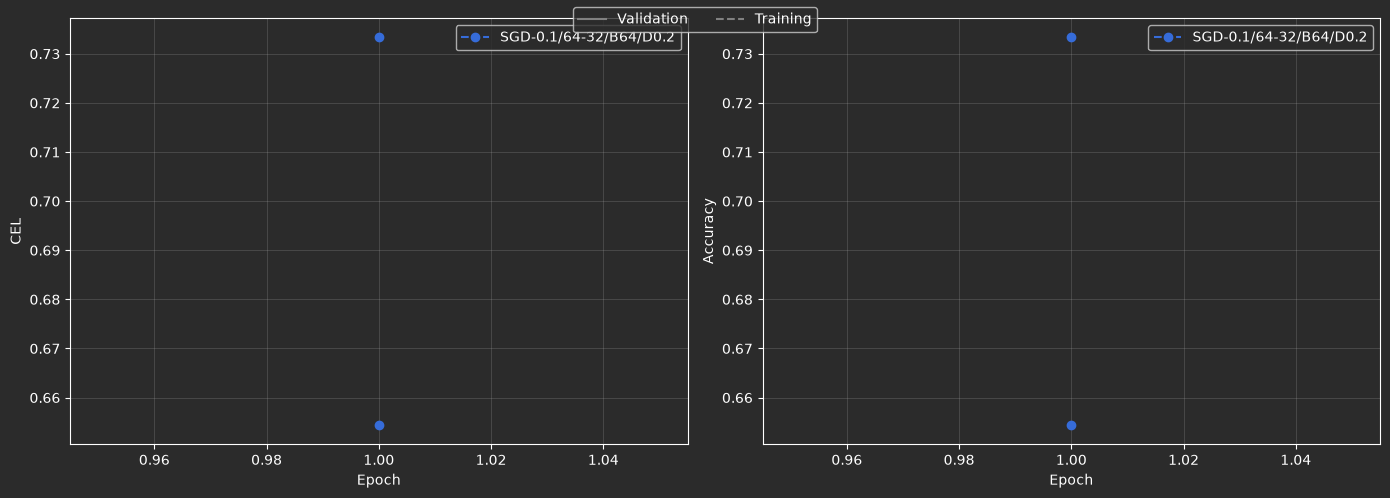

                        Train Loss  Valid Loss  Train Accuracy  Valid Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Worst Class Recall  Generalization Gap  Loss Gap  CM Deviation  Training Time  GPU max VRAM
SGD-0.1/64-32/B64/D0.2        0.74        1.04            0.73            0.65           0.65             0.75          0.65      0.63                0.10                0.08      0.30          3.02          10.55         18.81

--- Best experiments ---
Max Test Accuracy      -> SGD-0.1/64-32/B64/D0.2: 0.6497
Max Valid Accuracy     -> SGD-0.1/64-32/B64/D0.2: 0.6544
Max Macro F1           -> SGD-0.1/64-32/B64/D0.2: 0.6257
Best Worst-Class Recall -> SGD-0.1/64-32/B64/D0.2: 0.1000
Min CM Deviation       -> SGD-0.1/64-32/B64/D0.2: 3.0221
Min Training Time       -> SGD-0.1/64-32/B64/D0.2: 10.5s
Min VRAM       -> SGD-0.1/64-32/B64/D0.2: 18.8076171875 MB


In [4]:
viewAftermath(aftermath)